# Racing: Learn MPC cost networks with SHAC

Learn to follow the reference lap using an MPC cost network trained with SHAC.

At each control step, solve the following MPC problem in the standard optimal control form
from the [TurboMPC paper](https://arxiv.org/pdf/2606.24039#page=2), with inequality slack **enabled**:

$$
\begin{aligned}
\min_{x,u,\xi}\quad
& \sum_{t=0}^{N-1}\ell_t^\theta(x_t,u_t,x_{t+1},u_{t+1})
  +\ell_N^\theta(x_N,u_N)+\frac{\gamma_\xi}{2}\sum_{t=0}^{N}\|\xi_t\|_2^2 \\
\text{subject to}\quad
& x_0=x_{\mathrm{init}}, \\
& f_t(x_t,u_t,x_{t+1},u_{t+1})=0, &&t=0,\ldots,N-1, \\
& \underline g_t\le g_t(x_t,u_t)+\xi_t\le\overline g_t, &&t=0,\ldots,N.
\end{aligned}
$$

The running and terminal costs are
$$
\begin{aligned}
\ell_t^\theta &= \|x_t-x_t^{\mathrm{ref}}\|_{Q_\theta}^2
 +\|u_t-u_t^{\mathrm{ref}}\|_{R_\theta}^2
 +\tfrac12\|u_{t+1}-u_t\|_{W}^2, \\
\ell_N^\theta &= \|x_N-x_N^{\mathrm{ref}}\|_{Q_{f,\theta}}^2
 +\|u_N-u_N^{\mathrm{ref}}\|_{R_\theta}^2+10\,t_{\mathrm{elapsed},N},
\end{aligned}
$$
where $\|v\|_M^2=v^\top Mv$. The network predicts the diagonal weights
$Q_\theta,R_\theta,Q_{f,\theta}$ from the current observation.
$W=\operatorname{diag}(20000,10^{-5},10^{-9})$ and $\gamma_\xi=10^5$ are fixed.

The state is $x=(r,V,\beta,\omega_r,e,\Delta\psi,t_{\mathrm{elapsed}})$ and the control is
$u=(\delta,\tau_r,\tau_f)$: steering, combined motor/rear-brake torque, and front-brake torque.
The elapsed-time state starts at zero; its terminal linear cost weight is fixed at **10**.
The equality $f_t=0$ uses implicit trapezoidal integration of the path-coordinate vehicle model
on $N=40$ intervals of $\Delta s=3$ m, covering **120 m**. The controller replans at **50 Hz**
and holds each input for **0.02 s**.

The inequalities collect state and actuator bounds, including the track corridor,
$0.5\le V\le30$ m/s, and $(-0.5,-4000,-5000)\le u\le(0.5,370,0)$
(steering in radians, torques in N·m). Each upper and lower bound has its own signed slack $\xi_t$.
The applied control is clipped to the actuator limits.
SHAC trains the cost network through MPC and the simulator.

This code uses synthetic data and parameters, and does not represent any manufacturer's product.

## Imports

Install this checkout with `pip install -e '.[rl]'`. GPU execution also needs
CUDA-enabled JAX and PyTorch. Choose `DEVICE` before running; restart the kernel to change it.

In [1]:
import json
import os
import sys
from copy import copy
from pathlib import Path
from time import perf_counter

DEVICE = "cuda"  # "cpu" or "cuda"
os.environ["JAX_PLATFORMS"] = DEVICE
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "examples/rl").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from examples.rl.racing_training_experiment import build, configure_jax

configure_jax()
import jax
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from examples.rl.util.training import save_checkpoint

%matplotlib inline

if DEVICE == "cuda":
    if not torch.cuda.is_available() or any(d.platform != "gpu" for d in jax.devices()):
        raise RuntimeError("Both PyTorch and JAX must use CUDA.")
print(f"Torch: {DEVICE}; JAX: {jax.devices()}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")

Torch: cuda; JAX: [CudaDevice(id=0)]
GPU: NVIDIA GeForce RTX 5090


## RL task loss

Training starts are sampled uniformly over `s ∈ [37.4, 551.5] m`, with state
perturbations from [shac_mpc.yaml](configs/shac_mpc.yaml).

The fixed task loss penalizes tracking error and boundary violations at the next simulated state:
$$
\ell_{\mathrm{task}}(s)=\frac{20}{6}\sum_{i=1}^{6}\left(\frac{\varepsilon_i(s)}{d_i}\right)^2+500\,b(s),
\qquad d=(1,5,0.5,5,1,1),
$$
where $\varepsilon$ contains the reference-tracking errors in $(r,V,\beta,\omega_r,e,\Delta\psi)$.
With $[a]_+=\max(0,a)$, the boundary penalty is
$$
b(s)=\left(\frac{[9.5-V]_+}{30}\right)^2
+\left(\frac{[e_{\min}(s)-e]_+}{5}\right)^2
+\left(\frac{[e-e_{\max}(s)]_+}{5}\right)^2
+[|\Delta\psi|-\pi/3]_+^2.
$$
The reward is $r_t=-\ell_{\mathrm{task}}(s_{t+1})$, with an additional penalty of 50
on early termination from low speed, excessive heading error, or leaving the track.
A nonfinite transition receives reward $-50$. This notebook terminates off-track episodes immediately.

RL minimizes the negative expected discounted return,
$$\mathcal L_{\mathrm{RL}}(\theta)=-\mathbb E\!\left[\sum_{t=0}^{T-1}\gamma^t r_t\right],\qquad\gamma=0.99.$$
SHAC uses short differentiable rollouts with a target critic for the remaining return.
These reward weights stay fixed while the MPC cost network is trained.

## MPC setup

Use **one SQP iteration per control step**, **inequality slack**, and the state and
actuator bounds defined above. Each solve uses a shifted warm start.

In [2]:
UPDATES = 100
NUM_ENVS = 64
MPC_HORIZON = 40
TERMINAL_TIME_WEIGHT = 10.0
ROLLOUT_LENGTH = 16
SEED = 0

RUN_DIR = ROOT / "results/rl/racing_training"
config = yaml.safe_load((ROOT / "examples/rl/configs/shac_mpc.yaml").read_text())
config["training"]["device"] = DEVICE
config["training"]["actor"]["weights_linear_penalization_final_state"][-1] = TERMINAL_TIME_WEIGHT
config["env"]["off_track_grace_steps"] = 0
config["solver"].update(
    forward_backend="admm_fused_cudss" if DEVICE == "cuda" else "admm_jax_loop_jax_dense",
    backward_backend="direct_cudss_ffi" if DEVICE == "cuda" else "direct_jax_dense",
)

## SHAC learner

The actor predicts MPC costs; the critic estimates future reward beyond each
16-step training rollout. Both networks have two hidden layers of width 256.

### Exploration noise

During training, add independent Gaussian noise to the first MPC control, then clip:
$$u_t=\operatorname{clip}(u_t^{\mathrm{MPC}}+\epsilon_t,u_{\min},u_{\max}),
\qquad\epsilon_t\sim\mathcal N(0,\operatorname{diag}(\sigma^2)).$$
For $(\delta,\tau_r,\tau_f)$, the default is $\sigma=(0.0025,5,10)$
(steering in radians, torques in N·m).
The standard deviations stay fixed (`learn_sigma=False`). Evaluation disables this
noise; initial-state perturbations are sampled separately.

In [3]:
config["env"]["horizon"] = MPC_HORIZON
config["training"]["batch_size"] = NUM_ENVS
config["training"]["actor"].update(hidden_sizes=[256, 256], activation="relu")
config["training"]["critic"]["hidden_sizes"] = [256, 256]
config["training"]["shac"].update(
    seed=SEED,
    total_updates=UPDATES,
    training_horizon=ROLLOUT_LENGTH,
    critic_iterations=4,
    critic_minibatches=2,
)

learner = build(config)
print(f"Learning {learner.runtime.policy_parameter_dim} MPC cost parameters.")

Learning 17 MPC cost parameters.


## Training

### Training loop

Run exactly 100 updates from a fresh policy. `collect()` runs the differentiable
rollout; `update()` trains the actor and critic. The first update includes JAX
compilation; record the duration of every update.

In [4]:
history = []
for update in range(1, UPDATES + 1):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    started = perf_counter()
    rollout = learner.collect()
    metrics = {**rollout.metrics, **learner.update(rollout)}
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    metrics["iteration_seconds"] = perf_counter() - started
    history.append({"update": update, **metrics})
    print(
        f"{update:3d}/{UPDATES}  reward={metrics['rollout/reward_mean']:.3f}  "
        f"valid={metrics['rollout/valid_fraction']:.1%}  "
        f"actor_grad={metrics['train/actor_gradient_norm']:.3g}  "
        f"time={metrics['iteration_seconds']:.1f}s"
    )
RUN_DIR.mkdir(parents=True, exist_ok=True)
save_checkpoint(learner, RUN_DIR / "checkpoint.pt")
(RUN_DIR / "config.yaml").write_text(yaml.safe_dump(config, sort_keys=False))
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))
print(f"Saved trained policy to {RUN_DIR}")

  1/100  reward=-0.018  valid=100.0%  actor_grad=0.00282  time=37.9s
  2/100  reward=-0.039  valid=100.0%  actor_grad=0.00386  time=0.6s
  3/100  reward=-0.063  valid=100.0%  actor_grad=0.00536  time=0.6s
  4/100  reward=-0.093  valid=100.0%  actor_grad=0.00675  time=0.6s
  5/100  reward=-0.125  valid=100.0%  actor_grad=0.00676  time=0.6s
  6/100  reward=-0.148  valid=100.0%  actor_grad=0.0096  time=0.6s
  7/100  reward=-0.160  valid=100.0%  actor_grad=0.00671  time=0.6s
  8/100  reward=-0.165  valid=100.0%  actor_grad=0.0054  time=0.6s
  9/100  reward=-0.166  valid=100.0%  actor_grad=0.00609  time=0.6s
 10/100  reward=-0.160  valid=100.0%  actor_grad=0.0067  time=0.6s
 11/100  reward=-0.141  valid=100.0%  actor_grad=0.00651  time=0.6s
 12/100  reward=-0.116  valid=100.0%  actor_grad=0.00665  time=0.6s
 13/100  reward=-0.098  valid=100.0%  actor_grad=0.00692  time=0.6s
 14/100  reward=-0.091  valid=100.0%  actor_grad=0.00627  time=0.6s
 15/100  reward=-0.086  valid=100.0%  actor_grad=0

### Training outputs

`RUN_DIR` stores the checkpoint, configuration, and training history.
Plot the mean rollout reward and critic loss below.

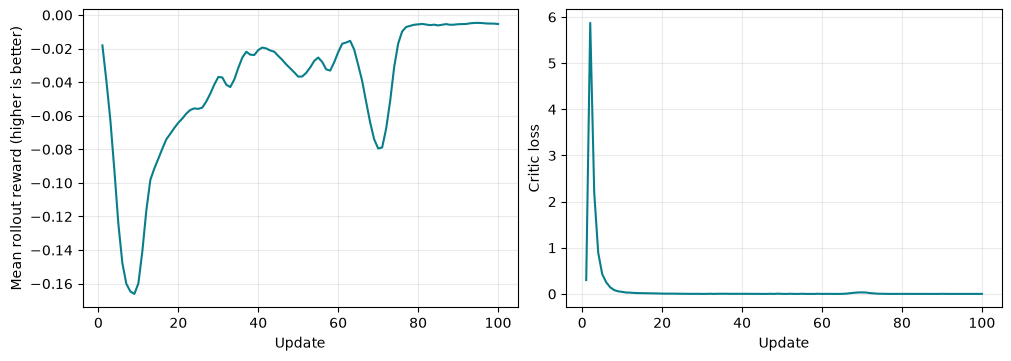

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, key, label in zip(
    axes,
    ("rollout/reward_mean", "train/value_loss"),
    ("Mean rollout reward (higher is better)", "Critic loss"),
):
    ax.plot([r["update"] for r in history], [r[key] for r in history], color="#087e8b")
    ax.set(xlabel="Update", ylabel=label)
    ax.grid(alpha=0.25)
plt.show()

## Evaluation

Compare nominal and trained MPC from the same reference state at `s = 293 m` for one
**258.5 m lap**, with no exploration, state noise, physics randomization, or resets.
Nominal MPC uses fixed costs; trained MPC uses the network. Both share the dynamics,
constraints, solver settings, and warm-start rules.

Stop each car at the finish, on failure, or after 40 s. Off-track failure is immediate.
Interpolate the final crossing to measure lap time; report incomplete laps as failures.

In [6]:
NAMES = ("Nominal MPC", "Trained MPC")
COLORS = ("#64748b", "#087e8b")
MAX_SECONDS = 40.0

# Copy the runtime so evaluation does not alter the training episode settings.
runtime = copy(learner.runtime)
runtime.initial_s = runtime.lap_start
dt = runtime.env.dt
limit = int(np.ceil(MAX_SECONDS / dt))
runtime.max_episode_steps = limit + 1
finish = runtime.lap_start + runtime.lap_length
fixed_costs = torch.as_tensor(
    runtime.initial_policy_parameters(), device=runtime.device, dtype=runtime.dtype
).reshape(1, -1)
evaluation_seed = learner.hyperparameters.seed + learner.evaluation_seed_offset
state = runtime.reset(
    2, evaluation_seed, evaluation=True, from_start=True, randomize_physics=False
)
active = torch.ones(2, device=runtime.device, dtype=torch.bool)
times = [0.0]
states = [state.state.cpu().numpy().copy()]
controls = [state.applied_control]
status = ["running", "running"]
stop_times, stop_indices = [None, None], [None, None]
failed_solves = np.zeros(2, dtype=int)

### Roll out one lap

The active mask freezes each car after it finishes or fails, while the other car continues.

In [7]:
actor_was_training = learner.actor.training
learner.actor.eval()
try:
    with torch.no_grad():
        for step in range(1, limit + 1):
            learned_costs = learner.policy_parameters(runtime.observe(state)[1:2])
            costs = torch.cat((fixed_costs, learned_costs), dim=0)
            policy = runtime.policy(costs, state, retain=False, active=active)
            transition = runtime.step(state, policy.mean, policy, active=active)
            physical = transition.state.state.cpu().numpy().copy()
            recorded = states[-1].copy()
            elapsed = step * dt

            for row, name in enumerate(NAMES):
                if status[row] != "running":
                    continue
                failed_solves[row] += int(transition.metrics["mpc_solve_failed"][row])
                finite = bool(np.isfinite(physical[row]).all())
                if finite:
                    recorded[row] = physical[row]
                if not finite or bool(transition.done[row]):
                    status[row] = "invalid" if not finite else next(
                        (key for key in ("invalid", "stall_reset", "off_track", "spin_out")
                         if bool(transition.metrics[key][row])),
                        "episode ended",
                    )
                    stop_times[row] = elapsed
                elif states[-1][row, -1] < finish <= physical[row, -1]:
                    fraction = (finish - states[-1][row, -1]) / (
                        physical[row, -1] - states[-1][row, -1]
                    )
                    recorded[row] = states[-1][row] + fraction * (
                        physical[row] - states[-1][row]
                    )
                    recorded[row, -1] = finish
                    stop_times[row] = float(elapsed - dt + fraction * dt)
                    status[row] = "finished"
                elif step == limit:
                    status[row], stop_times[row] = "time limit", elapsed
                if status[row] != "running":
                    stop_indices[row] = step
                    active[row] = False
                    outcome = (
                        f"{stop_times[row]:.3f} s" if status[row] == "finished"
                        else f"failure ({status[row]}) at {stop_times[row]:.2f} s"
                    )
                    print(f"{name}: {outcome}", flush=True)

            times.append(elapsed)
            states.append(recorded)
            controls.append(transition.state.applied_control)
            state = transition.state
            if all(outcome != "running" for outcome in status):
                break
finally:
    learner.actor.train(actor_was_training)

Trained MPC: 15.734 s
Nominal MPC: 15.823 s


## Results

### Metrics

Compute errors over each car's actual traveled distance, including failed laps.
Completion percentage makes the different evaluation lengths explicit.

In [8]:
times, states = map(np.asarray, (times, states))
controls = torch.stack(controls).cpu().numpy()
table = {key: np.asarray(value) for key, value in runtime.env.track.table.items()}
results = {}
for row, name in enumerate(NAMES):
    end = stop_indices[row] + 1
    row_time, row_state = times[:end].copy(), states[:end, row].copy()
    row_time[-1] = stop_times[row]
    progress = row_state[:, -1] - runtime.lap_start
    wrapped = runtime.lap_start + np.remainder(progress, runtime.lap_length)
    speed_error = row_state[:, 1] - np.interp(wrapped, table["s"], table["V"])
    lateral = row_state[:, 4]
    heading = np.rad2deg(row_state[:, 5])
    results[name] = {
        "time": row_time,
        "state": row_state,
        "control": controls[:end, row],
        "progress": progress,
        "speed_error": speed_error,
        "heading_error": heading,
        "statistics": {
            "status": status[row],
            "lap_time_s": stop_times[row] if status[row] == "finished" else None,
            "elapsed_s": stop_times[row],
            "distance_m": float(progress[-1]),
            "completion_pct": float(100 * progress[-1] / runtime.lap_length),
            "lateral_rmse_m": float(np.sqrt(np.mean(lateral**2))),
            "lateral_max_m": float(np.max(np.abs(lateral))),
            "speed_rmse_m_s": float(np.sqrt(np.mean(speed_error**2))),
            "heading_rmse_deg": float(np.sqrt(np.mean(heading**2))),
            "mpc_failed_steps": int(failed_solves[row]),
        },
    }

In [9]:
statistics = {name: result["statistics"] for name, result in results.items()}
metrics = (
    ("status", "Status", ""),
    ("lap_time_s", "Lap time (s)", ".3f"),
    ("elapsed_s", "Elapsed time (s)", ".3f"),
    ("distance_m", "Distance traveled (m)", ".1f"),
    ("completion_pct", "Lap completed (%)", ".1f"),
    ("lateral_rmse_m", "Lateral RMSE (m)", ".3f"),
    ("lateral_max_m", "Maximum lateral error (m)", ".3f"),
    ("speed_rmse_m_s", "Speed RMSE (m/s)", ".3f"),
    ("heading_rmse_deg", "Heading RMSE (°)", ".3f"),
    ("mpc_failed_steps", "Failed MPC solves", "d"),
)
lines = ["| Metric | Nominal MPC | Trained MPC |", "|---|---:|---:|"]
for key, label, number_format in metrics:
    values = [statistics[name][key] for name in NAMES]
    values = ["failure" if value is None else format(value, number_format) for value in values]
    lines.append(f"| {label} | {' | '.join(values)} |")
display(Markdown("\n".join(lines)))
(RUN_DIR / "lap_comparison.json").write_text(json.dumps(statistics, indent=2));

| Metric | Nominal MPC | Trained MPC |
|---|---:|---:|
| Status | finished | finished |
| Lap time (s) | 15.823 | 15.734 |
| Elapsed time (s) | 15.823 | 15.734 |
| Distance traveled (m) | 258.5 | 258.5 |
| Lap completed (%) | 100.0 | 100.0 |
| Lateral RMSE (m) | 0.210 | 0.031 |
| Maximum lateral error (m) | 0.354 | 0.062 |
| Speed RMSE (m/s) | 0.325 | 0.041 |
| Heading RMSE (°) | 0.673 | 0.155 |
| Failed MPC solves | 0 | 0 |

### Plots

Plot both closed-loop trajectories against the reference track.

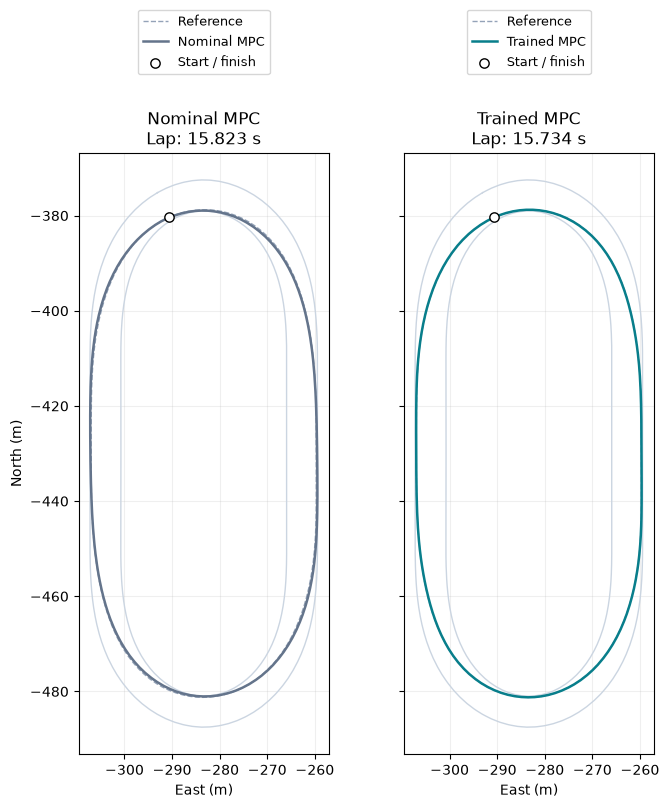

In [10]:
runtime = learner.runtime
table = {key: np.asarray(value) for key, value in runtime.env.track.table.items()}


def track_value(position, key):
    wrapped = runtime.lap_start + np.remainder(position - runtime.lap_start, runtime.lap_length)
    return np.interp(wrapped, table["s"], table[key])


def track_xy(position, lateral):
    phi = track_value(position, "phi")
    return (
        track_value(position, "E") - lateral * np.cos(phi),
        track_value(position, "N") - lateral * np.sin(phi),
    )


grid = np.linspace(runtime.lap_start, runtime.lap_start + runtime.lap_length, 1001)
fig, axes = plt.subplots(1, 2, figsize=(7, 8), sharex=True, sharey=True, layout="constrained")
for ax, (name, result), color in zip(axes, results.items(), COLORS):
    for bound in ("e_min", "e_max"):
        ax.plot(*track_xy(grid, track_value(grid, bound)), color="#cbd5e1", linewidth=1)
    ax.plot(*track_xy(grid, 0), color="#94a3b8", linestyle="--", linewidth=1, label="Reference")
    states = result["state"]
    x, y = track_xy(states[:, -1], states[:, 4])
    ax.plot(x, y, color=color, linewidth=1.8, label=name)
    ax.scatter(x[0], y[0], s=45, facecolor="white", edgecolor="black", zorder=4, label="Start / finish")
    s = result["statistics"]
    finished = s["lap_time_s"] is not None
    if not finished:
        ax.scatter(x[-1], y[-1], marker="x", s=65, color=color, linewidth=2, zorder=5, label="failure")
    outcome = f"Lap: {s['lap_time_s']:.3f} s" if finished else f"failure: {s['completion_pct']:.1f}% of lap"
    ax.set(title=f"{name}\n{outcome}", xlabel="East (m)", aspect="equal")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.12), fontsize=9)
axes[0].set_ylabel("North (m)")
plt.show()

Plot lateral, speed, and heading errors against distance traveled.

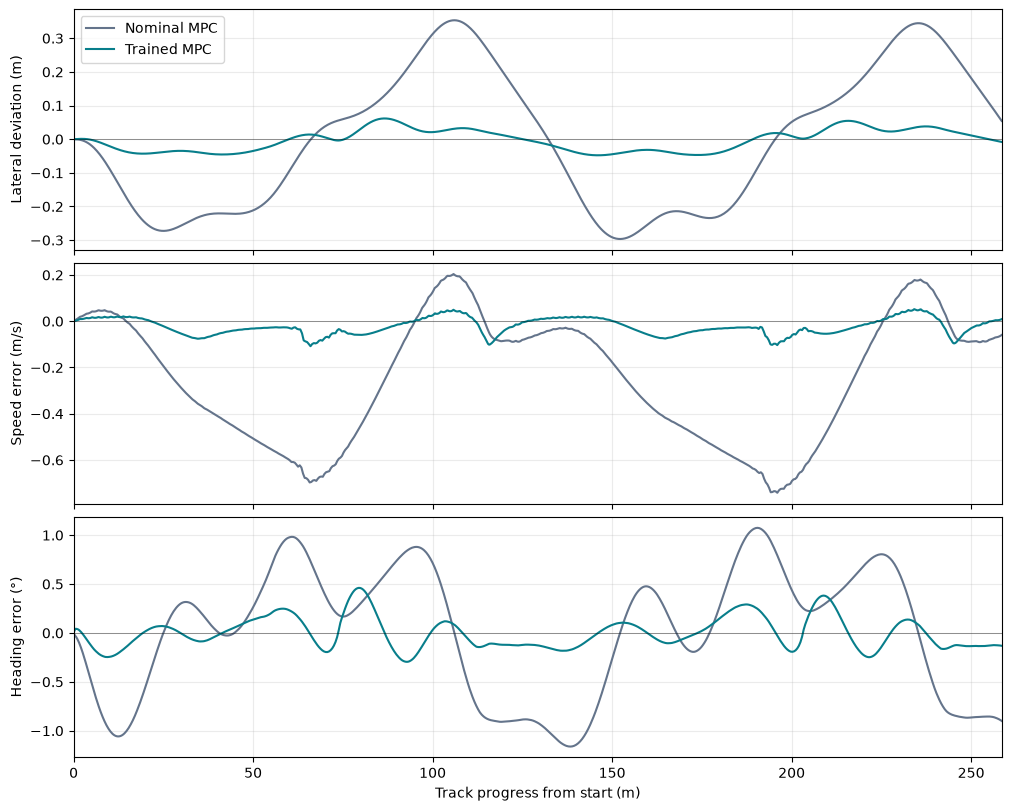

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for (name, result), color in zip(results.items(), COLORS):
    deviations = (
        result["state"][:, 4], result["speed_error"], result["heading_error"],
    )
    for ax, values in zip(axes, deviations):
        ax.plot(result["progress"], values, label=name, color=color)
    if result["statistics"]["lap_time_s"] is None:
        failure_s = result["progress"][-1]
        for ax in axes:
            ax.axvline(failure_s, color=color, linestyle=":", alpha=0.6)
        axes[0].scatter(failure_s, deviations[0][-1], marker="x", s=55,
                        color="#b91c1c", linewidth=2, zorder=5)
        axes[0].annotate(
            f"failure ({result['statistics']['status']})",
            (failure_s, deviations[0][-1]), xytext=(10, 12), textcoords="offset points",
            color="#b91c1c", fontsize=9,
        )

axes[0].legend()
for ax, label in zip(axes, ("Lateral deviation (m)", "Speed error (m/s)", "Heading error (°)")):
    ax.axhline(0, color="black", linewidth=0.7, alpha=0.4)
    ax.set(ylabel=label, xlim=(0, runtime.lap_length))
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Track progress from start (m)")
plt.show()